<a href="https://colab.research.google.com/github/ckurtz/teaching_UPC_UFRMI/blob/main/CLIP_tutorial_(with_medical_images_ROCO).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Notebook created in 2024 with the help of Xiaoyang Wei, Phd student at LIPADE, Université Paris Cité

# Interacting with CLIP

This is a self-contained notebook that shows how to download and run CLIP models, calculate the similarity between arbitrary image and text inputs, and perform zero-shot image classifications.

# Preparation for Colab

Make sure you're running a GPU runtime; if not, select "GPU" as the hardware accelerator in Runtime > Change Runtime Type in the menu. The next cells will install the `clip` package and its dependencies, and check if PyTorch 1.7.1 or later is installed.

In [ ]:
! pip install ftfy regex tqdm
! pip install git+https://github.com/openai/CLIP.git

  Cloning https://github.com/openai/CLIP.git to /tmp/pip-req-build-e_jg8fb1
  Running command git clone --filter=blob:none --quiet https://github.com/openai/CLIP.git /tmp/pip-req-build-e_jg8fb1
  Resolved https://github.com/openai/CLIP.git to commit d05afc436d78f1c48dc0dbf8e5980a9d471f35f6
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for clip: filename=clip-1.0-py3-none-any.whl size=1369548 sha256=2f63c1990f3fa4695ffdc0d1c57b563d16868973cbb9a243159096a7474def34
  Stored in directory: /tmp/pip-ephem-wheel-cache-plbktyuz/wheels/cb/a8/74/5f32d6cf0407457f0f62737b6da5c14eb86b9cac476fdf630d
Successfully built clip


# Loading the model

`clip.available_models()` will list the names of available CLIP models.

In [ ]:
import clip
import numpy as np

clip.available_models()

['RN50',
 'RN101',
 'RN50x4',
 'RN50x16',
 'RN50x64',
 'ViT-B/32',
 'ViT-B/16',
 'ViT-L/14',
 'ViT-L/14@336px']

In [ ]:
model, preprocess = clip.load("ViT-B/16")
model.cuda().eval()
input_resolution = model.visual.input_resolution
context_length = model.context_length
vocab_size = model.vocab_size

print("Model parameters:", f"{np.sum([int(np.prod(p.shape)) for p in model.parameters()]):,}")
print("Input resolution:", input_resolution)
print("Context length:", context_length)
print("Vocab size:", vocab_size)

100%|███████████████████████████████████████| 335M/335M [00:06<00:00, 55.2MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Model parameters: 149,620,737
Input resolution: 224
Context length: 77
Vocab size: 49408


In [ ]:
model.cuda().eval()

CLIP(
  (visual): VisionTransformer(
    (conv1): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16), bias=False)
    (ln_pre): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
    (transformer): Transformer(
      (resblocks): Sequential(
        (0): ResidualAttentionBlock(
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
          )
          (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
          (mlp): Sequential(
            (c_fc): Linear(in_features=768, out_features=3072, bias=True)
            (gelu): QuickGELU()
            (c_proj): Linear(in_features=3072, out_features=768, bias=True)
          )
          (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
        )
        (1): ResidualAttentionBlock(
          (attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_fe

# Image Preprocessing

We resize the input images and center-crop them to conform with the image resolution that the model expects. Before doing so, we will normalize the pixel intensity using the dataset mean and standard deviation.

The second return value from `clip.load()` contains a torchvision `Transform` that performs this preprocessing.



In [ ]:
preprocess

Compose(
    Resize(size=224, interpolation=bicubic, max_size=None, antialias=True)
    CenterCrop(size=(224, 224))
    <function _convert_image_to_rgb at 0x7fdfcc5f5760>
    ToTensor()
    Normalize(mean=(0.48145466, 0.4578275, 0.40821073), std=(0.26862954, 0.26130258, 0.27577711))
)

# Text Preprocessing

We use a case-insensitive tokenizer, which can be invoked using `clip.tokenize()`. By default, the outputs are padded to become 77 tokens long, which is what the CLIP models expects.

In [ ]:
clip.tokenize("Hello World!")

tensor([[49406,  3306,  1002,   256, 49407,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0,     0,     0,     0,
             0,     0,     0,     0,     0,     0,     0]], dtype=torch.int32)

# Setting up input images and texts

We are going to feed 8 example natrural/medical images and their textual descriptions to the model, and compare the similarity between the corresponding features.

The tokenizer is case-insensitive, and we can freely give any suitable textual descriptions.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
import os

data_path = "/content/drive/MyDrive/data"

print("Dataset exists:", os.path.exists(data_path))

if os.path.exists(data_path):
    print("Contents:", os.listdir(data_path)[:10])

Dataset exists: True
Contents: ['roco-list.csv', 'local-val-list.csv', 'ViT-B-16_best_checkpoint_2.tar', 'pretrain_data', 'knowledge']


In [ ]:
import pandas as pd
import os

data_path = "/content/drive/MyDrive/data"

df = pd.read_csv(os.path.join(data_path, "roco-list.csv"))

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset shape: (65405, 2)
Columns: ['A', 'B']


,A,B
0,ROCO_00002.jpg,Computed tomography scan in axial view showing...
1,ROCO_00003.jpg,Bacterial contamination occurred after complet...
2,ROCO_00004.jpg,The patient had residual paralysis of the hand...
3,ROCO_00005.jpg,Panoramic radiograph after immediate loading.\n
4,ROCO_00007.jpg,Plain abdomen x-ray: Multiple air levels at th...


In [ ]:
import os

image_folder = "/content/drive/MyDrive/data/pretrain_data"

print(os.listdir(image_folder)[:20])

['train_umls.txt', 'roco']


In [ ]:
roco_path = "/content/drive/MyDrive/data/pretrain_data/roco"

print(os.listdir(roco_path)[:20])

['test', 'train', 'val']


In [ ]:
import os

test_path = "/content/drive/MyDrive/data/pretrain_data/roco/test"

print(os.listdir(test_path)[:20])

['radiology', 'non-radiology']


In [ ]:
import os

radiology_path = "/content/drive/MyDrive/data/pretrain_data/roco/test/radiology"

print(os.listdir(radiology_path)[:20])

['keywords.txt', 'semtypes.txt', 'dlinks.txt', 'licences.txt', 'captions.txt', 'cuis.txt', 'images']


In [ ]:
import os

images_path = "/content/drive/MyDrive/data/pretrain_data/roco/test/radiology/images"

image_files = os.listdir(images_path)

print("Number of images:", len(image_files))
print("First images:", image_files[:10])

Number of images: 8179
First images: ['ROCO_70992.jpg', 'ROCO_70977.jpg', 'ROCO_70947.jpg', 'ROCO_70978.jpg', 'ROCO_70964.jpg', 'ROCO_70952.jpg', 'ROCO_70993.jpg', 'ROCO_70995.jpg', 'ROCO_70996.jpg', 'ROCO_71013.jpg']


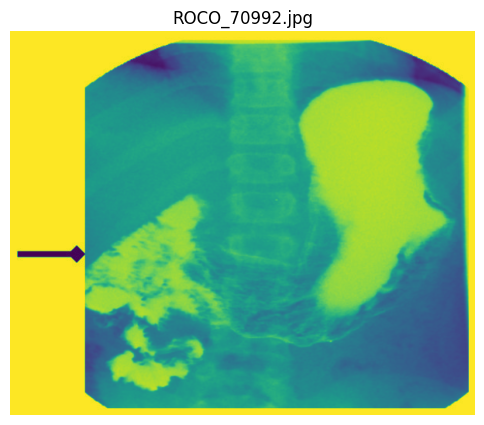

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

image_name = image_files[0]
image = Image.open(os.path.join(images_path, image_name))

plt.figure(figsize=(6, 6))
plt.imshow(image)
plt.title(image_name)
plt.axis("off")
plt.show()

In [ ]:
captions_path = "/content/drive/MyDrive/data/pretrain_data/roco/test/radiology/captions.txt"

with open(captions_path, "r", encoding="utf-8") as f:
    lines = f.readlines()

image_id = "ROCO_70992"

for line in lines:
    if line.startswith(image_id + "\t"):
        print("Caption:", line.split("\t", 1)[1].strip())
        break
else:
    print("Caption not found")

Caption: Duodenum and the small bowel lying on the right side of the midline (arrow).


In [ ]:
import torch
import clip
import numpy as np

captions = [
    "Duodenum and the small bowel lying on the right side of the midline (arrow).",
    "A chest X-ray showing the lungs.",
    "An MRI scan of the brain.",
    "A CT scan of the abdomen.",
    "An X-ray showing a fractured bone."
]

In [ ]:
# Prepare the image
image_input = preprocess(image).unsqueeze(0).cuda()

# Tokenize candidate captions
text_input = clip.tokenize(captions).cuda()

with torch.no_grad():
    # Extract embeddings
    image_features = model.encode_image(image_input)
    text_features = model.encode_text(text_input)

    # Normalize embeddings
    image_features /= image_features.norm(dim=-1, keepdim=True)
    text_features /= text_features.norm(dim=-1, keepdim=True)

    # Calculate cosine similarities
    similarities = (image_features @ text_features.T).squeeze(0)

# Display results
scores = similarities.cpu().numpy()

for caption, score in sorted(zip(captions, scores), key=lambda x: -x[1]):
    print(f"{score:.4f} | {caption}")

0.3135 | Duodenum and the small bowel lying on the right side of the midline (arrow).
0.2927 | A CT scan of the abdomen.
0.2725 | An X-ray showing a fractured bone.
0.2720 | A chest X-ray showing the lungs.
0.2135 | An MRI scan of the brain.


In [ ]:
# images to use and their textual descriptions
descriptions = {
    "page": "a page of text about segmentation",
    "chelsea": "a facial photo of a tabby cat",
    "astronaut": "a portrait of an astronaut with the American flag",
    "rocket": "a rocket standing on a launchpad",
    "motorcycle_right": "a red motorcycle standing in a garage",
    "camera": "a person looking at a camera on a tripod",
    "horse": "a black-and-white silhouette of a horse",
    "coffee": "a cup of coffee on a saucer"
}

med_descriptions = {
    "ROCO_00002": "CT scan in axial view showing obliteration of the left maxillary sinus",
    "ROCO_00017": "Coronary angiogram demonstrating occluded arteries",
    "ROCO_00028": "T2 weighted MRI image showing foraminal extensions of the cysts",
    "ROCO_00033": "Lytic lesions (arrows) involving the humerus.",
    "ROCO_00050": "Free air beneath the diaphragm at abdominal x-ray film",
    "ROCO_00056": "View of giant cell tumor of thumb metacarpal preoperatively",
    "ROCO_00060": "Transverse view of lung using CT.Leukemic infiltration is seen.",
    "ROCO_00135": "CT scan showing multiple non-communicating cysts in liver and kidney"
}

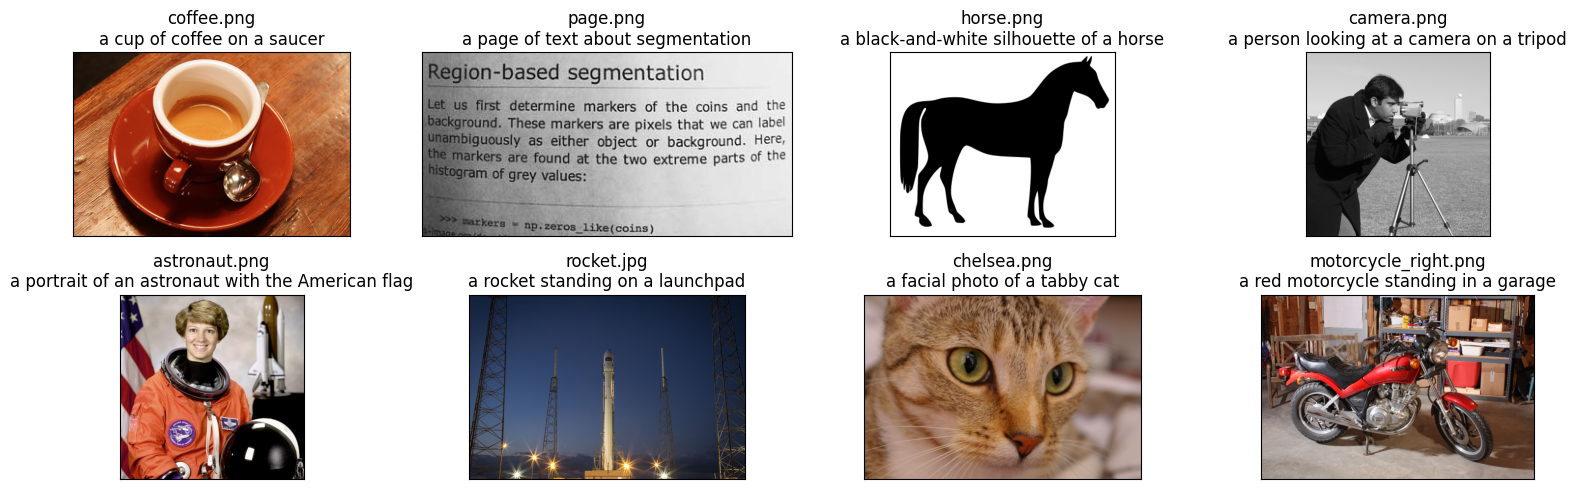

In [ ]:
import skimage
import skimage.data
import os
import matplotlib.pyplot as plt
original_images = []
images = []
texts = []
plt.figure(figsize=(16, 5))

skimage.data.download_all(directory=None)
for filename in [filename for filename in os.listdir(skimage.data_dir) if filename.endswith(".png") or filename.endswith(".jpg")]:
    name = os.path.splitext(filename)[0]
    if name not in descriptions:
        continue

    image = Image.open(os.path.join(skimage.data_dir, filename)).convert("RGB")

    plt.subplot(2, 4, len(images) + 1)
    plt.imshow(image)
    plt.title(f"{filename}\n{descriptions[name]}")
    plt.xticks([])
    plt.yticks([])

    original_images.append(image)
    images.append(preprocess(image))
    texts.append(descriptions[name])

plt.tight_layout()


## Building features

We normalize the images, tokenize each text input, and run the forward pass of the model to get the image and text features.

In [ ]:
image_input = torch.tensor(np.stack(images)).cuda()
text_tokens = clip.tokenize(["This is " + desc for desc in texts]).cuda()
with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    text_features = model.encode_text(text_tokens).float()

## Calculating cosine similarity

We normalize the features and calculate the dot product of each pair.

Text(0.5, 1.0, 'Cosine similarity between text and image features(natural)')

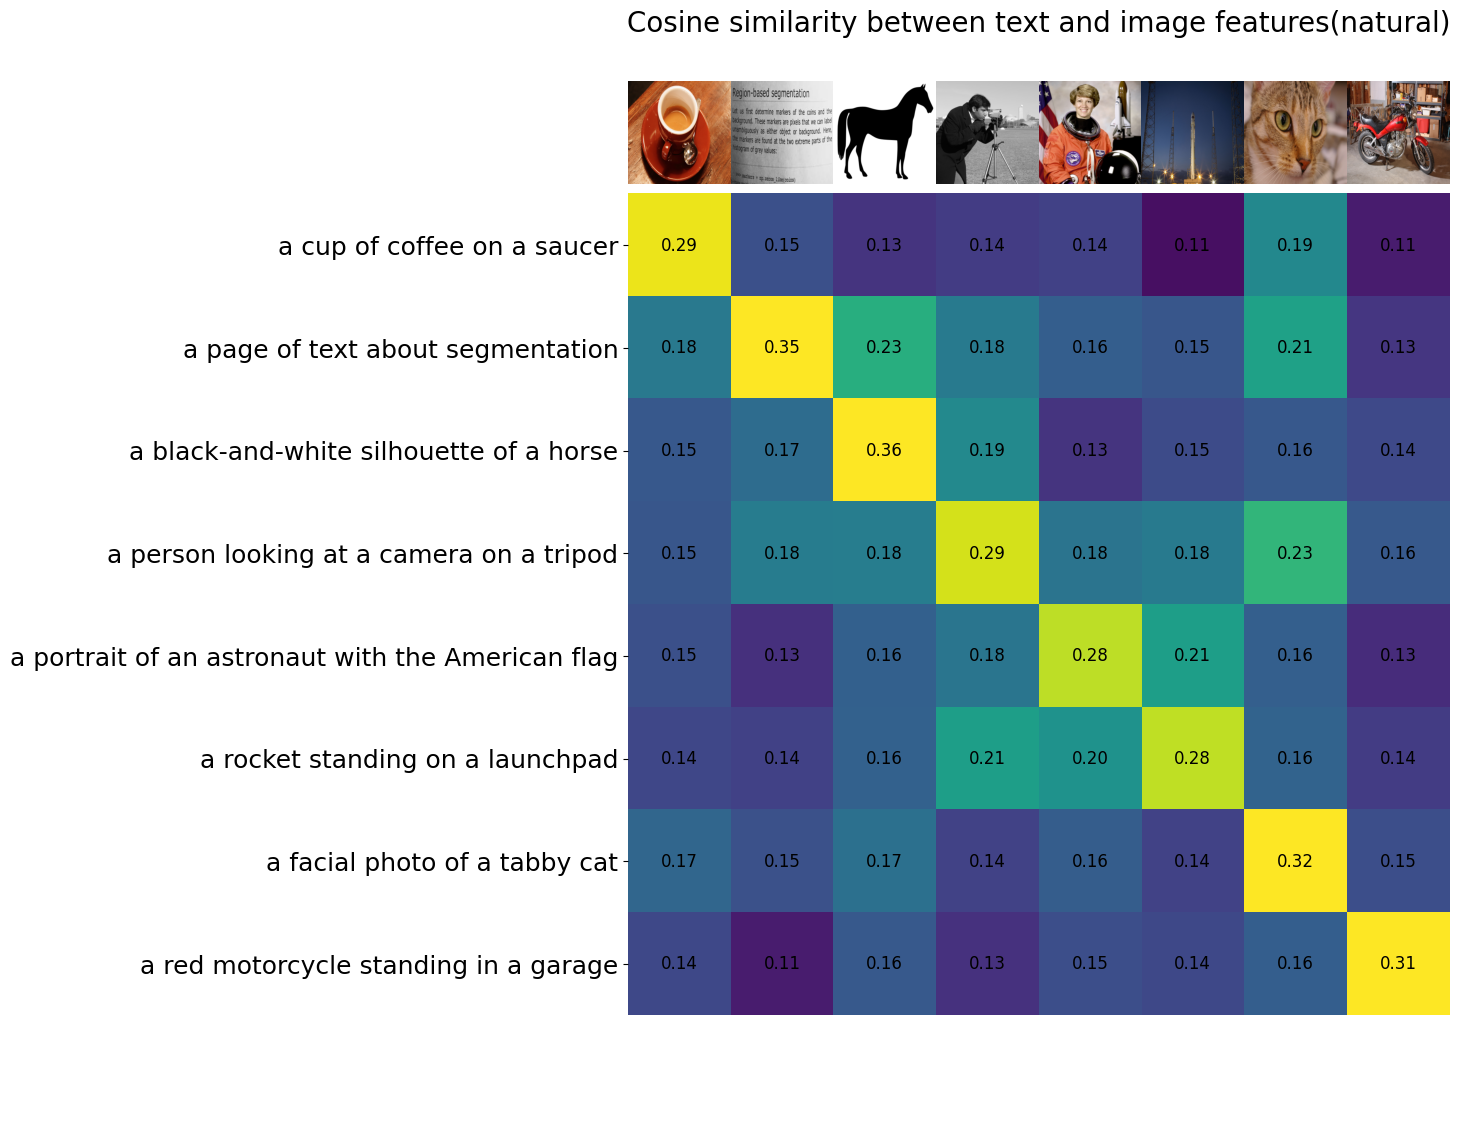

In [ ]:
image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

count = len(descriptions)

plt.figure(figsize=(20, 14))
plt.imshow(similarity, vmin=0.1, vmax=0.3)
# plt.colorbar()
plt.yticks(range(count), texts, fontsize=18)
plt.xticks([])
for i, image in enumerate(original_images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)

for side in ["left", "top", "right", "bottom"]:
  plt.gca().spines[side].set_visible(False)

plt.xlim([-0.5, count - 0.5])
plt.ylim([count + 0.5, -2])

plt.title("Cosine similarity between text and image features(natural)", size=20)

## Performance of CLIP in medical domain

Text(0.5, 1.0, 'Cosine similarity between text and image features(medical)')

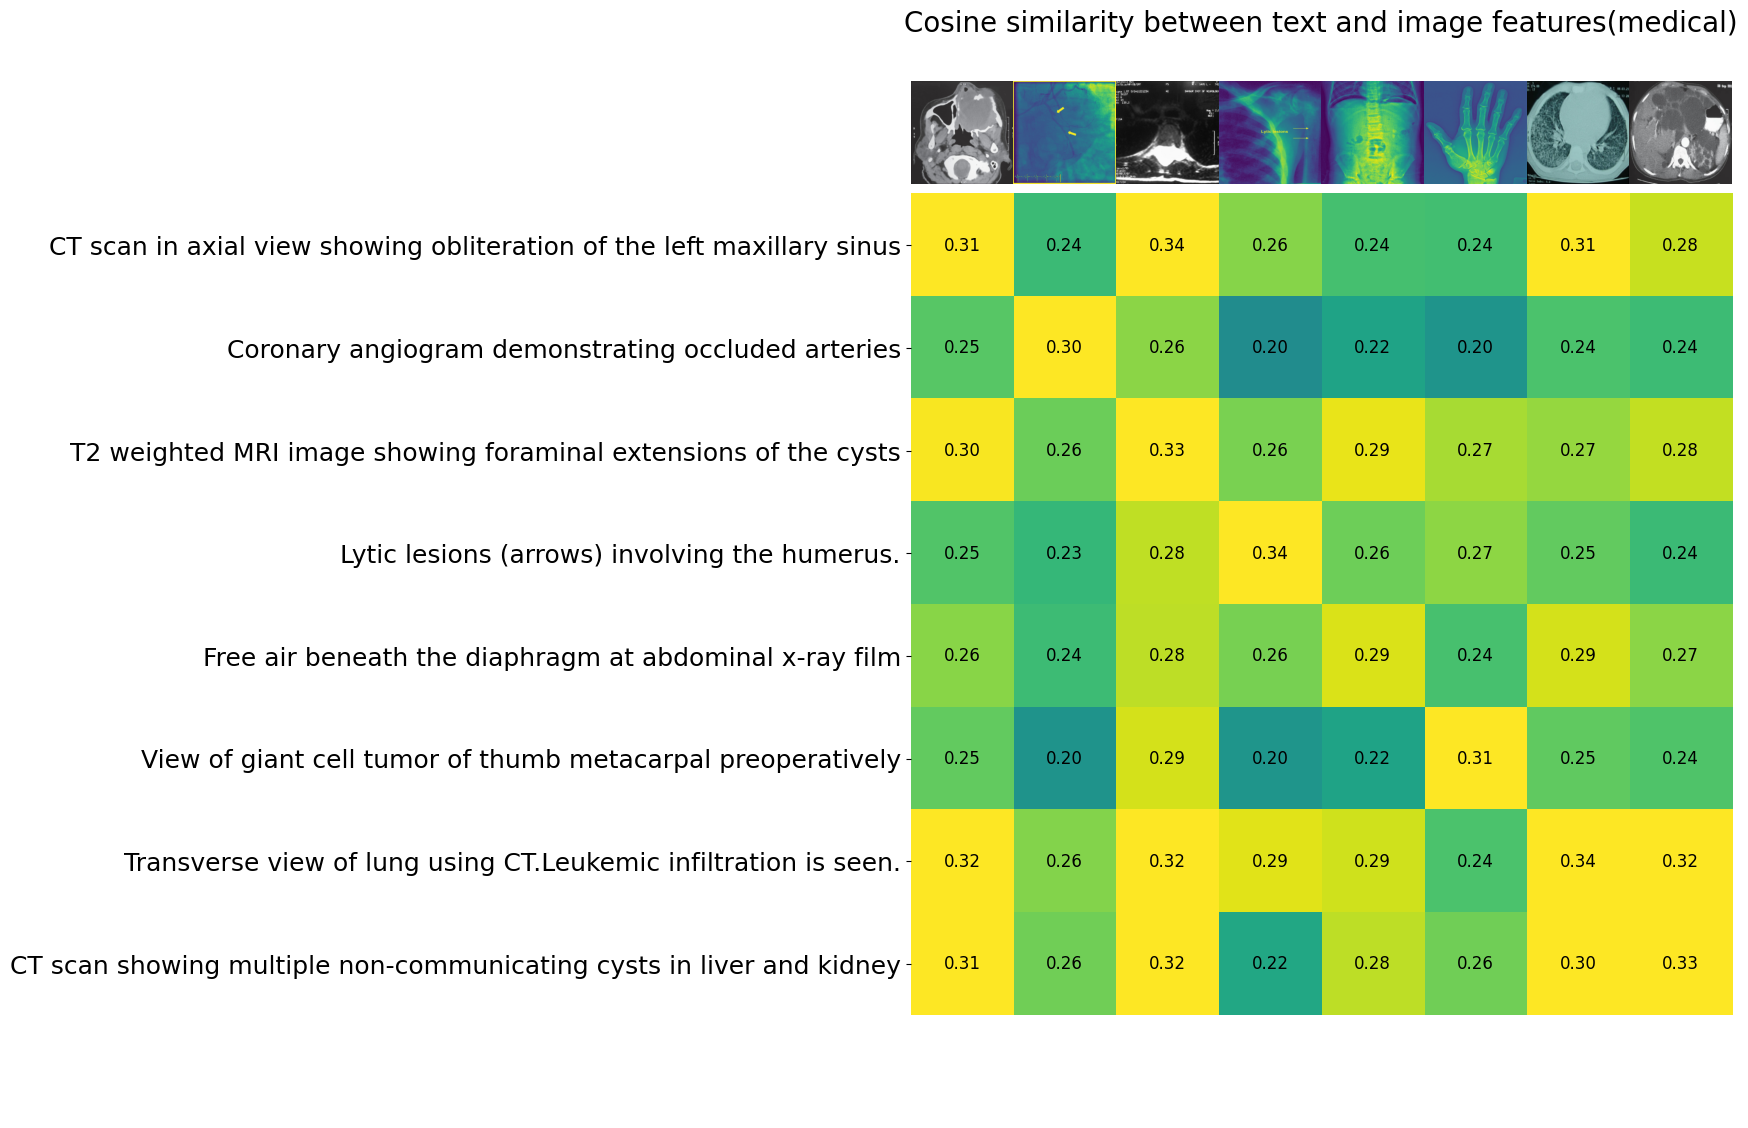

In [ ]:
original_images = []
images = []
texts = []
for filename in list(med_descriptions.keys()):
    image = Image.open(os.path.join("/content/drive/MyDrive/data/pretrain_data/roco/train/radiology/images", filename+'.jpg'))
    original_images.append(image)
    images.append(preprocess(image))
    texts.append(med_descriptions[filename])
image_input = torch.tensor(np.stack(images)).cuda()
text_tokens = clip.tokenize(["This is " + desc for desc in texts]).cuda()
with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    text_features = model.encode_text(text_tokens).float()
image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

count = len(descriptions)

plt.figure(figsize=(20, 14))
plt.imshow(similarity, vmin=0.1, vmax=0.3)
# plt.colorbar()
plt.yticks(range(count), texts, fontsize=18)
plt.xticks([])
for i, image in enumerate(original_images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)
for side in ["left", "top", "right", "bottom"]:
  plt.gca().spines[side].set_visible(False)

plt.xlim([-0.5, count - 0.5])
plt.ylim([count + 0.5, -2])

plt.title("Cosine similarity between text and image features(medical)", size=20)


# Zero-Shot Image Classification

You can classify images using the cosine similarity (times 100) as the logits to the softmax operation.

In [ ]:
from torchvision.datasets import CIFAR100

cifar100 = CIFAR100(os.path.expanduser("~/.cache"), transform=preprocess, download=True)

100%|██████████| 169M/169M [29:26<00:00, 95.7kB/s]


In [ ]:
text_descriptions = [f"This is a photo of a {label}" for label in cifar100.classes]
text_tokens = clip.tokenize(text_descriptions).cuda()

In [ ]:
with torch.no_grad():
    text_features = model.encode_text(text_tokens).float()
    text_features /= text_features.norm(dim=-1, keepdim=True)

text_probs = (100.0 * image_features @ text_features.T).softmax(dim=-1)
top_probs, top_labels = text_probs.cpu().topk(5, dim=-1)

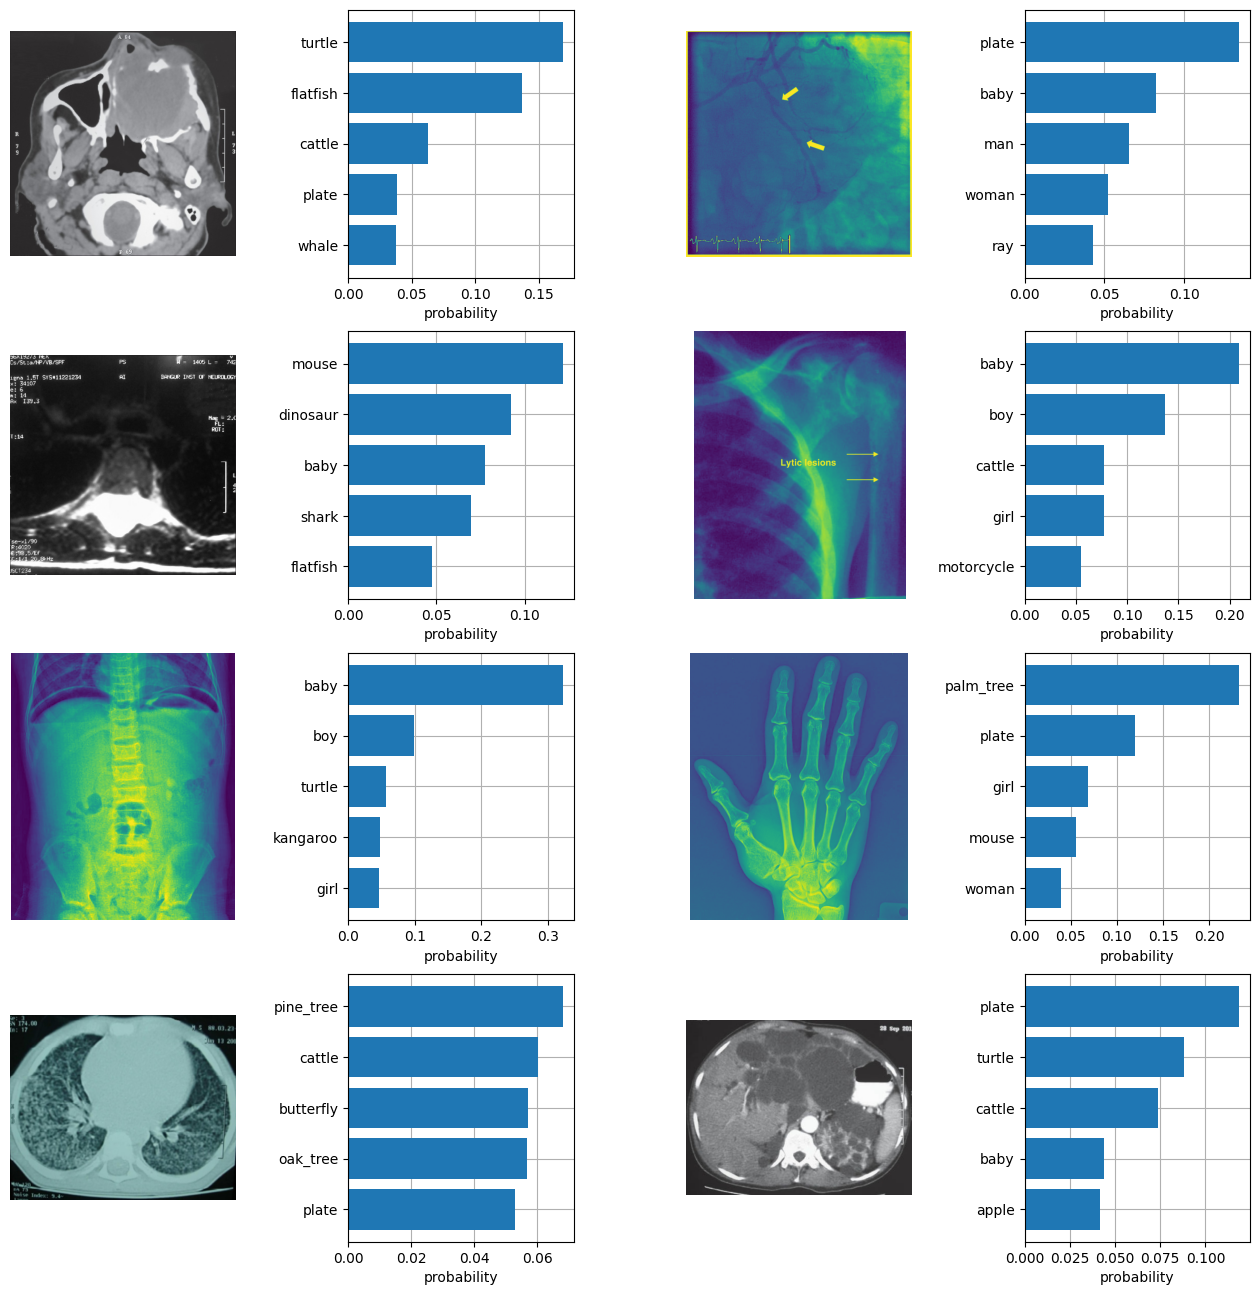

In [ ]:
plt.figure(figsize=(16, 16))

for i, image in enumerate(original_images):
    plt.subplot(4, 4, 2 * i + 1)
    plt.imshow(image)
    plt.axis("off")

    plt.subplot(4, 4, 2 * i + 2)
    y = np.arange(top_probs.shape[-1])
    plt.grid()
    plt.barh(y, top_probs[i])
    plt.gca().invert_yaxis()
    plt.gca().set_axisbelow(True)
    plt.yticks(y, [cifar100.classes[index] for index in top_labels[i].numpy()])
    plt.xlabel("probability")

plt.subplots_adjust(wspace=0.5)
plt.show()

# Fine-tuning CLIP on ROCO



In [ ]:
# Dataset location
csv_file = "/content/drive/MyDrive/data/roco-list.csv"
root_dir = "/content/drive/MyDrive/data/pretrain_data/roco/train/radiology/images"

val_csv_file = "/content/drive/MyDrive/data/local-val-list.csv"
val_root_dir = "/content/drive/MyDrive/data/pretrain_data/roco/val/radiology/images"

# Train options
seed = 42
batch_size = 16
image_size = 224
start_epoch = 0
epochs = 10
visual_encoder = "clip@ViT-B/16"
learning_rate = 3e-6

model_path = "/content/drive/MyDrive/model_checkpoint_CLIP_ROCO"


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import torchvision
import datetime
import time
from tqdm import tqdm
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
from torch.utils.data import Dataset
import random
import clip



class CLRDataset(Dataset):
    """Contrastive Learning Representations Dataset."""

    def __init__(self, csv_file, root_dir, transform=None, clip=False):
        self.clr_frame = pd.read_csv(csv_file)
        self.root_dir = root_dir
        self.transform = transform
        self.clip = clip

    def __len__(self):
        return len(self.clr_frame)

    def text_sampling(self, text):
        text = text.replace("\n", " ")
        text = text.split(".")
        if '' in text:
            text.remove('')
        text = random.choice(text)
        return text

    def __getitem__(self, idx):
        if torch.is_tensor(idx):
            idx = idx.tolist()

        img_name = os.path.join(self.root_dir,
                                self.clr_frame.iloc[idx, 0]
                                )
        if not os.path.exists(img_name):
            img_name=img_name.replace('train','val')
        image = Image.open(img_name)
        if not self.clip:
            image = image.convert('RGB')
        text = self.clr_frame.iloc[idx, 1]
        name = self.clr_frame.iloc[idx, 0]
        sample = {'image': image, 'text': text,'name':name}
        if self.clip:
            sample = self.transform(sample['image']), sample['text'],sample['name'] #self.text_sampling(sample['text'])
        elif self.transform:
            sample = self.transform(sample)

        return sample


def load_optimizer( model, lr=3e-6):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, epochs, eta_min=0, last_epoch=-1
    )
    return optimizer, scheduler


def train( train_loader, model, tokenizer, optimizer,truncation):
    loss_epoch = 0
    for step, (images, texts,name) in enumerate(train_loader):
        optimizer.zero_grad()
        x_v = images.to('cuda')
        x_u = tokenizer(list(texts), truncate=True).to('cuda')

        v,u=model(x_v,x_u)

        labels = torch.arange(batch_size, dtype=torch.long, device='cuda')

        loss_img = torch.nn.CrossEntropyLoss()
        loss_txt = torch.nn.CrossEntropyLoss()

        img_loss = loss_img(v,labels)
        text_loss = loss_txt(u,labels)

        loss = (img_loss + text_loss)/2

        loss.backward()
        optimizer.step()

        if step % 500 == 0:
            print(f"Step [{step}/{len(train_loader)}]\t Loss: {loss.item()}")

        loss_epoch += loss.item()
    return loss_epoch



def validate( val_loader, model, tokenizer, optimizer, truncation):

    with torch.no_grad():
        model.eval()
        loss_epoch = 0
        for step, (x_v, x_u) in enumerate(val_loader):
            x_v = x_v.to('cuda')
            x_u = tokenizer(list(x_u), truncate=True).to('cuda')

            v,u=model(x_v,x_u)

            labels = torch.arange(batch_size, dtype=torch.long, device='cuda')

            loss_img = torch.nn.CrossEntropyLoss()
            loss_txt = torch.nn.CrossEntropyLoss()

            img_loss = loss_img(v,labels)
            text_loss = loss_txt(u,labels)

            loss = (img_loss + text_loss)/2
            loss_epoch += loss.item()

    model.train()
    return loss_epoch


def main(gpu):

    is_master=True

    # set GPU device
    torch.cuda.set_device(gpu)
    torch.manual_seed(seed)
    np.random.seed(seed)

    # initialize model
    print("Initializing model... ", end="", flush=True)
    model, preprocess = clip.load(visual_encoder.split("@")[-1], device='cuda', jit=False)
    model.float()
    tokenizer=clip.tokenize
    train_fonction = train
    validate_fonction = validate

    # optimizer
    optimizer, scheduler = load_optimizer(model, lr=float(learning_rate))

    # initialize dataloader
    transform = preprocess
    print('Image_Transform',transform)
    train_dataset = CLRDataset(csv_file=csv_file,
                               root_dir=root_dir,
                               transform=transform,
                               clip = True
                               )

    val_dataset = CLRDataset(csv_file=val_csv_file,
                             root_dir=val_root_dir,
                             transform=transform,
                             clip = True
                             )

    train_sampler = None
    train_loader = torch.utils.data.DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=(train_sampler is None),
        drop_last=True,
        num_workers=8,
        sampler=train_sampler,
    )

    val_loader = torch.utils.data.DataLoader(
        val_dataset,
        batch_size=batch_size,
        drop_last=True,
        num_workers=8
    )

    print("[DONE]\n")
    print("STARTING TRAINING")
    print('Start Time =', datetime.datetime.now().strftime("%H:%M:%S"), '\n')

    t0 = time.time()
    global_step = 0
    current_epoch = 0
    best_val_loss = np.inf

    for epoch in range(0, epochs):
        if epoch<2:
            if train_sampler is not None:
                train_sampler.set_epoch(epoch)

            lr = optimizer.param_groups[0]["lr"]
            loss_epoch = train_fonction(train_loader, model, tokenizer, optimizer,True)

        if is_master:
            val_loss = validate_fonction( val_loader, model, tokenizer, optimizer, True)
            if val_loss < best_val_loss:
                torch.save(model.state_dict(), os.path.join(model_path, "best_checkpoint.pth"))
                best_val_loss = val_loss

            epoch_counter = epoch - 0
            elapsed = time.time() - t0
            epoch_time = elapsed/(epoch_counter+1)
            remaining = (epochs - (epoch_counter+1))*epoch_time
            remaining = str(datetime.timedelta(seconds=round(remaining)))
            elapsed = str(datetime.timedelta(seconds=round(elapsed)))
            print(f'Epoch {epoch_counter+1}/{epochs} [{elapsed}<{remaining}, {round(epoch_time, 2)}s/epoch] {round((epoch_counter+1)/epochs*100, 1)}% loss: {loss_epoch / len(train_loader)}\t val_loss: {val_loss / len(val_loader)} lr: {lr}')

            current_epoch += 1


if not os.path.exists(model_path):
    os.makedirs(model_path)

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("Device:", device)
main(0)

## Performance of CLIP in medical domain(after fine-tuning on ROCO )

Text(0.5, 1.0, 'Cosine similarity between text and image features(medical)')

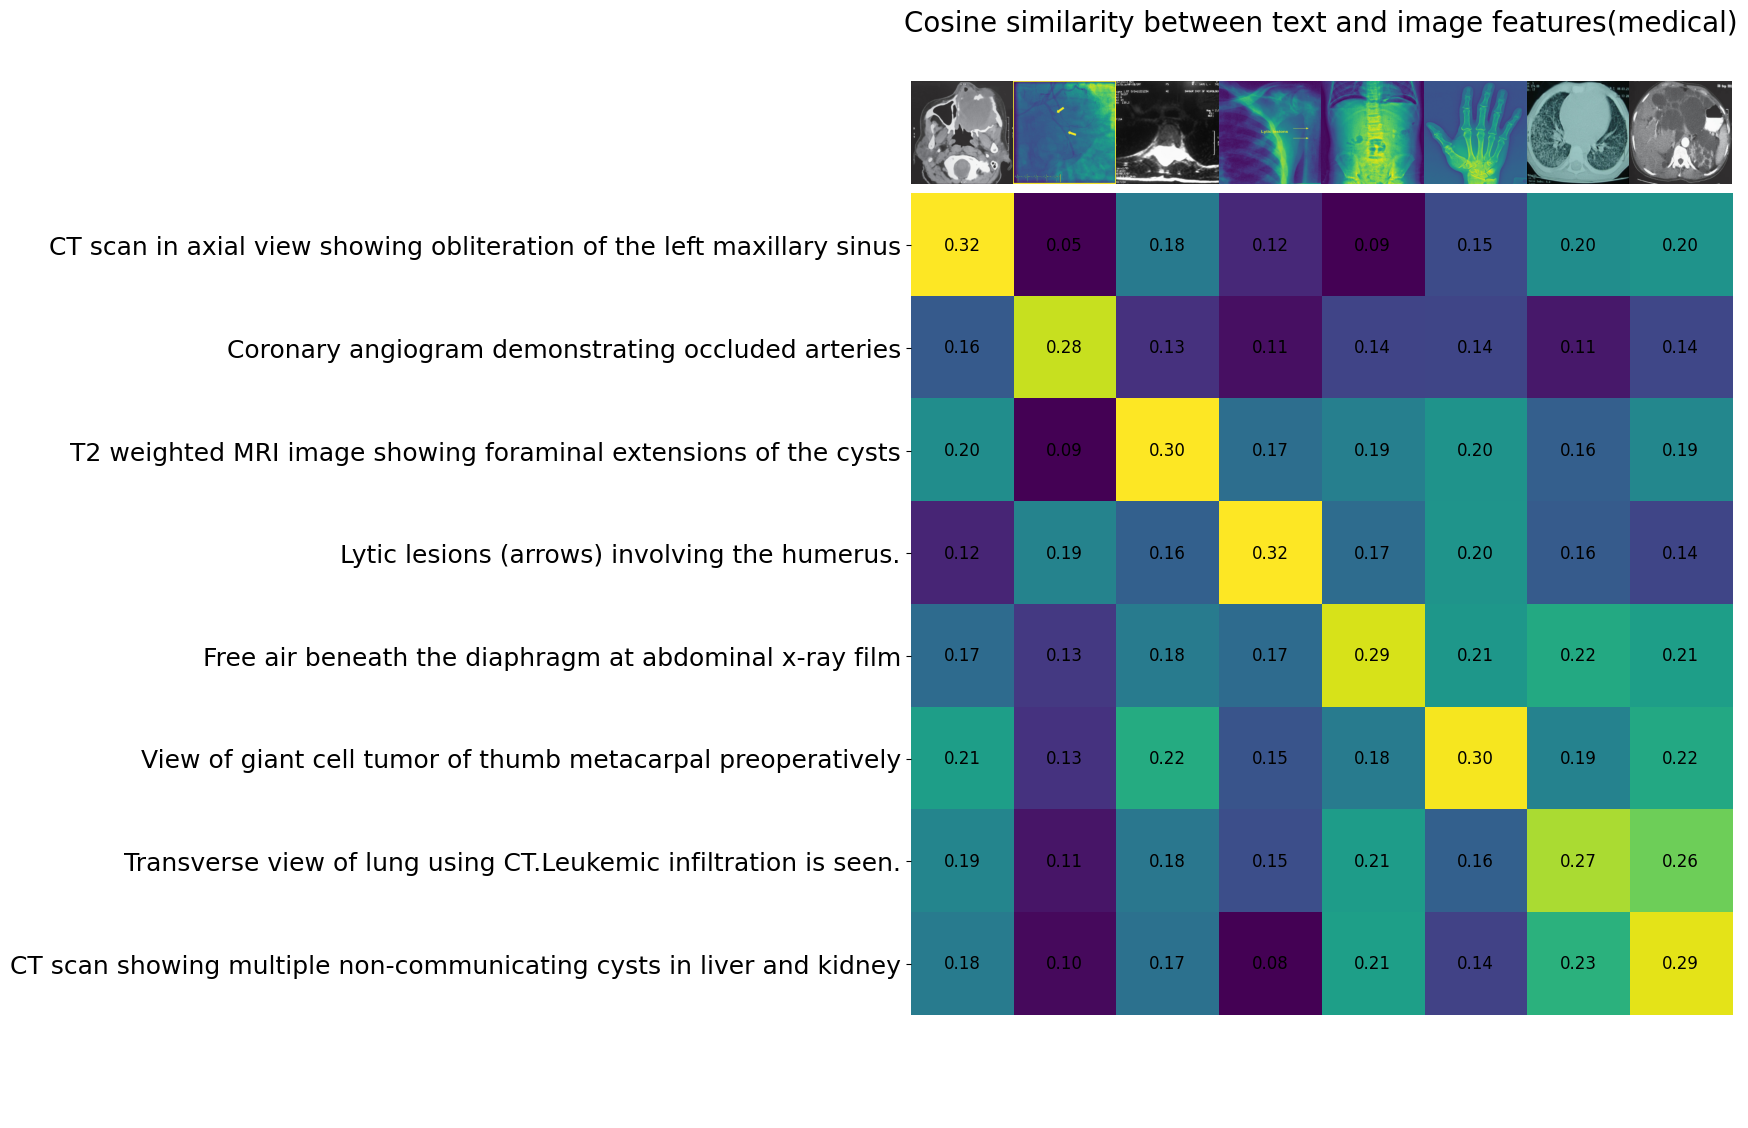

In [ ]:
# Load the fine-tuned CLIP checkpoint
checkpoint_path = "/content/drive/MyDrive/data/ViT-B-16_best_checkpoint_2.tar"

model.load_state_dict(
    torch.load(checkpoint_path, map_location="cuda", weights_only=True)
)

model.cuda().eval()

#compute txt-img similarity again
original_images = []
images = []
texts = []
for filename in list(med_descriptions.keys()):
    image = Image.open(os.path.join(root_dir, filename+'.jpg'))
    original_images.append(image)
    images.append(preprocess(image))
    texts.append(med_descriptions[filename])
image_input = torch.tensor(np.stack(images)).cuda()
text_tokens = clip.tokenize(["This is " + desc for desc in texts]).cuda()
with torch.no_grad():
    image_features = model.encode_image(image_input).float()
    text_features = model.encode_text(text_tokens).float()
image_features /= image_features.norm(dim=-1, keepdim=True)
text_features /= text_features.norm(dim=-1, keepdim=True)
similarity = text_features.cpu().numpy() @ image_features.cpu().numpy().T

count = len(descriptions)

plt.figure(figsize=(20, 14))
plt.imshow(similarity, vmin=0.1, vmax=0.3)
plt.yticks(range(count), texts, fontsize=18)
plt.xticks([])
for i, image in enumerate(original_images):
    plt.imshow(image, extent=(i - 0.5, i + 0.5, -1.6, -0.6), origin="lower")
for x in range(similarity.shape[1]):
    for y in range(similarity.shape[0]):
        plt.text(x, y, f"{similarity[y, x]:.2f}", ha="center", va="center", size=12)

for side in ["left", "top", "right", "bottom"]:
  plt.gca().spines[side].set_visible(False)

plt.xlim([-0.5, count - 0.5])
plt.ylim([count + 0.5, -2])

plt.title("Cosine similarity between text and image features(medical)", size=20)

## Task 2 — Compare CLIP models on ROCO

In [2]:
!pip install -q ftfy regex tqdm
!pip install -q git+https://github.com/openai/CLIP.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [6]:
import os
import random
import gc
import torch
import clip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch.nn.functional as F

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DATA = "/content/drive/MyDrive/data"
ROCO_DIR = f"{DATA}/pretrain_data/roco/test/radiology"
MODELS = ["RN50", "ViT-B/32", "ViT-B/16"]
N_ROCO = 100

# Same images and captions for all models
with open(f"{ROCO_DIR}/captions.txt", encoding="utf-8") as f:
    rows = [line.rstrip("\n").split("\t", 1) for line in f]

rows = [(os.path.join(ROCO_DIR, "images", parts[0] + ".jpg"), parts[1].strip())
        for parts in rows if len(parts) == 2 and parts[1].strip()]
random.Random(42).shuffle(rows)
roco_pairs = []
for path, caption in rows:
    if os.path.isfile(path):
        roco_pairs.append((path, caption))
    if len(roco_pairs) == N_ROCO:
        break
assert len(roco_pairs) == N_ROCO, "Not enough ROCO images found"
print("ROCO test pairs:", len(roco_pairs))

ROCO test pairs: 100


In [7]:
def roco_similarity(model, transform, pairs, batch_size=16):
    image_features = []
    text_features = []
    with torch.inference_mode():
        for start in range(0, len(pairs), batch_size):
            batch = pairs[start:start + batch_size]
            images = []
            for path, _ in batch:
                with Image.open(path) as img:
                    images.append(transform(img.convert("RGB")))
            images = torch.stack(images).to(DEVICE)
            tokens = clip.tokenize([caption for _, caption in batch], truncate=True).to(DEVICE)
            image_features.append(F.normalize(model.encode_image(images).float(), dim=-1).cpu())
            text_features.append(F.normalize(model.encode_text(tokens).float(), dim=-1).cpu())
    return torch.cat(image_features) @ torch.cat(text_features).T


def retrieval_scores(sim):
    target = torch.arange(sim.shape[0])
    ranking = sim.argsort(dim=1, descending=True)
    return {
        "Top-1 (%)": round((ranking[:, 0] == target).float().mean().item() * 100, 2),
        "Top-5 (%)": round((ranking[:, :5] == target[:, None]).any(dim=1).float().mean().item() * 100, 2)
    }

roco_results = []
roco_similarities = {}

for model_name in MODELS:
    print("Evaluating:", model_name)
    eval_model, eval_preprocess = clip.load(model_name, device=DEVICE, jit=False)
    eval_model.eval()
    sim = roco_similarity(eval_model, eval_preprocess, roco_pairs)
    roco_similarities[model_name] = sim
    roco_results.append({"Model": model_name, **retrieval_scores(sim)})
    del eval_model, eval_preprocess
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

roco_table = pd.DataFrame(roco_results)
display(roco_table)

Evaluating: RN50


100%|███████████████████████████████████████| 244M/244M [00:09<00:00, 25.9MiB/s]
/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Evaluating: ViT-B/32


100%|███████████████████████████████████████| 338M/338M [00:10<00:00, 32.3MiB/s]


Evaluating: ViT-B/16


100%|███████████████████████████████████████| 335M/335M [00:07<00:00, 43.9MiB/s]


,Model,Top-1 (%),Top-5 (%)
0,RN50,19.0,48.0
1,ViT-B/32,17.0,47.0
2,ViT-B/16,23.0,53.0


## Task 3 — More medical examples

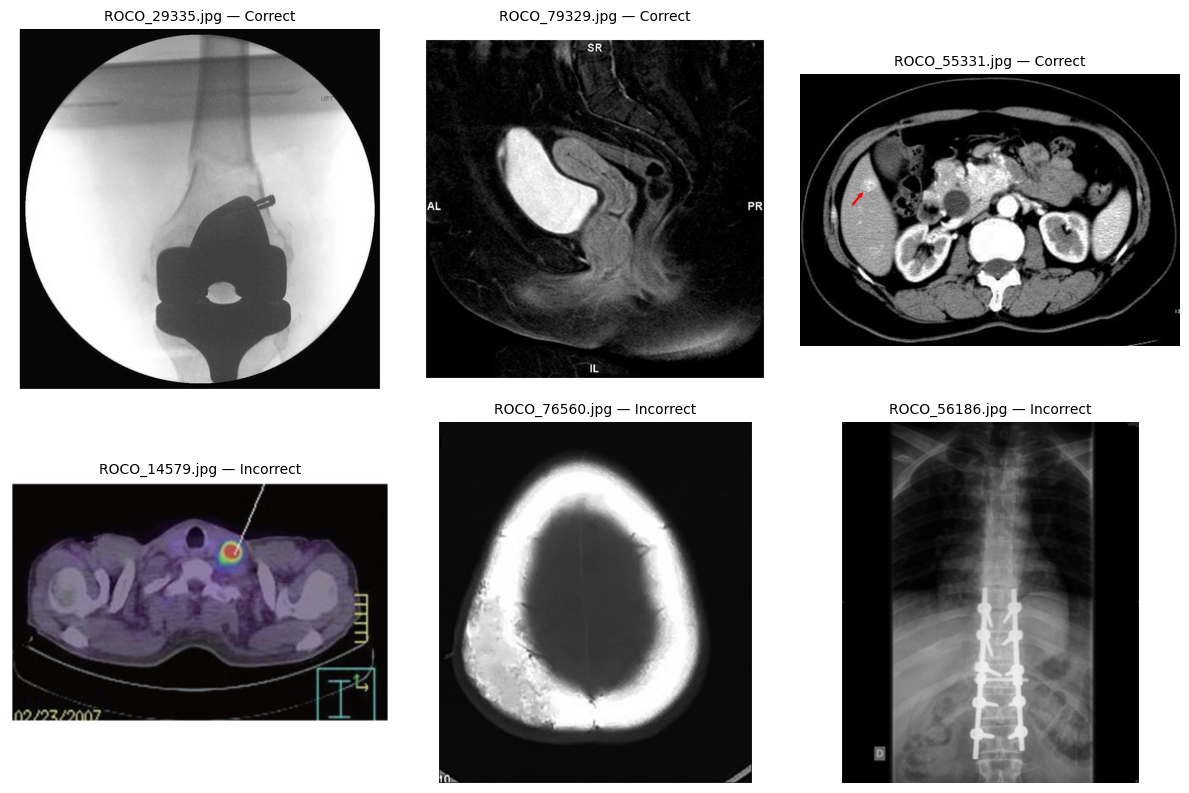


 ROCO_29335.jpg
True: Intraoperative view of left femoral periprosthetic fracture after reduction and staple removal
Predicted: Intraoperative view of left femoral periprosthetic fracture after reduction and staple removal
Similarity: 0.343

 ROCO_79329.jpg
True: T2-weighted MRI of the pelvic characterized a 4.6 × 4.2 × 4.0 centimeter mass located within the anterior vaginal wall with mild homogeneous enhancement.
Predicted: T2-weighted MRI of the pelvic characterized a 4.6 × 4.2 × 4.0 centimeter mass located within the anterior vaginal wall with mild homogeneous enhancement.
Similarity: 0.351

 ROCO_55331.jpg
True: TACE in a 59-year-old female with multiple liver metastases form pancreatic neuroendocrine tumorA. Contrast-enhanced CT before TACE revealed a segment 6 hypovascular liver metastasis in the arterial phase (arrow) B. contrast-enhanced CT showed a significant decrease in the lesion at 6 months after treatment (arrow).
Predicted: TACE in a 59-year-old female with multiple liv

In [8]:
# Examples from the ROCO test set
sim = roco_similarities["ViT-B/16"]
pred = sim.argmax(dim=1)
correct = (pred == torch.arange(len(roco_pairs)))

correct_ids = torch.where(correct)[0].tolist()[:3]
wrong_ids = torch.where(~correct)[0].tolist()[:3]
example_ids = correct_ids + wrong_ids

fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax in axes.flat:
    ax.axis("off")
for ax, i in zip(axes.flat, example_ids):
    path, true_caption = roco_pairs[i]
    with Image.open(path) as img:
        ax.imshow(img.convert("RGB"))
    label = "Correct" if correct[i].item() else "Incorrect"
    ax.set_title(f"{os.path.basename(path)} — {label}", fontsize=10)
plt.tight_layout()
plt.show()

for i in example_ids:
    path, true_caption = roco_pairs[i]
    predicted_caption = roco_pairs[pred[i].item()][1]
    print("\n", os.path.basename(path))
    print("True:", true_caption)
    print("Predicted:", predicted_caption)
    print("Similarity:", round(sim[i, pred[i]].item(), 3))

## Task 4 — Zero-shot classification on CIFAR-10

In [9]:
from torchvision.datasets import CIFAR10

cifar10 = CIFAR10(root="/content/cifar10", train=False, download=True)
class_names = cifar10.classes

# 100 test images per class
rng = random.Random(42)
indices = []
for label in range(len(class_names)):
    class_indices = [i for i, y in enumerate(cifar10.targets) if y == label]
    indices.extend(rng.sample(class_indices, 100))
rng.shuffle(indices)

prompts = [f"a photo of a {name.replace('_', ' ')}" for name in class_names]
print("Images:", len(indices), "Classes:", len(class_names))

100%|██████████| 170M/170M [39:12<00:00, 72.5kB/s]


Images: 1000 Classes: 10


In [10]:
def cifar10_predictions(model, transform, indices, batch_size=64):
    tokens = clip.tokenize(prompts).to(DEVICE)
    with torch.inference_mode():
        text_features = F.normalize(model.encode_text(tokens).float(), dim=-1)
        predictions = []
        for start in range(0, len(indices), batch_size):
            batch = indices[start:start + batch_size]
            images = torch.stack([transform(cifar10[i][0].convert("RGB")) for i in batch]).to(DEVICE)
            image_features = F.normalize(model.encode_image(images).float(), dim=-1)
            predictions.extend((image_features @ text_features.T).argmax(dim=1).cpu().tolist())
    return np.array(predictions)

true_labels = np.array([cifar10.targets[i] for i in indices])
cifar_results = []
cifar_predictions = {}

for model_name in MODELS:
    print("Evaluating:", model_name)
    eval_model, eval_preprocess = clip.load(model_name, device=DEVICE, jit=False)
    eval_model.eval()
    predictions = cifar10_predictions(eval_model, eval_preprocess, indices)
    cifar_predictions[model_name] = predictions
    accuracy = (predictions == true_labels).mean() * 100
    cifar_results.append({"Model": model_name, "Accuracy (%)": round(accuracy, 2)})
    del eval_model, eval_preprocess
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

display(pd.DataFrame(cifar_results))

Evaluating: RN50


/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


Evaluating: ViT-B/32
Evaluating: ViT-B/16


,Model,Accuracy (%)
0,RN50,69.3
1,ViT-B/32,88.9
2,ViT-B/16,88.1


,Class,Accuracy (%)
0,airplane,87.0
1,automobile,99.0
2,bird,90.0
3,cat,88.0
4,deer,85.0
5,dog,94.0
6,frog,63.0
7,horse,96.0
8,ship,92.0
9,truck,87.0


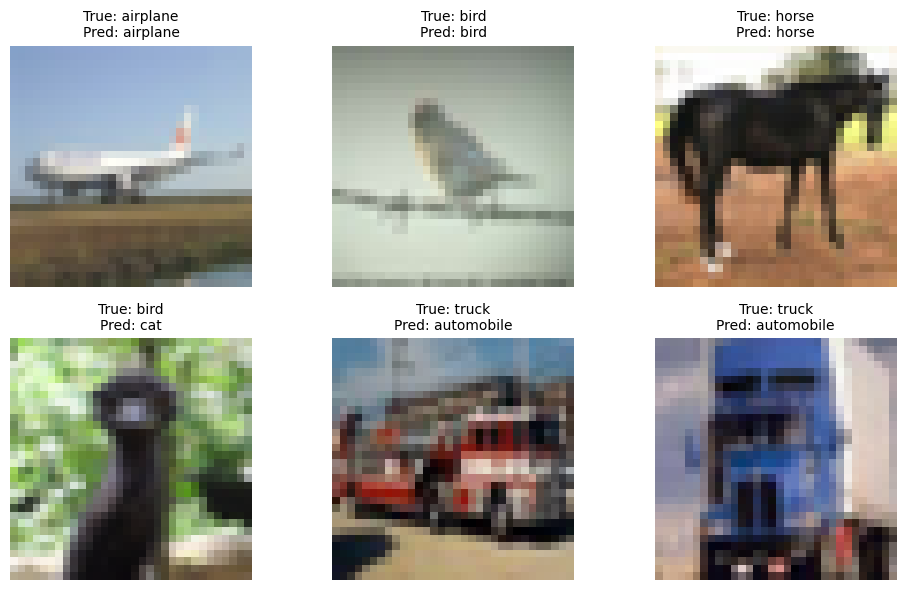

In [11]:
# Accuracy by class (ViT-B/16)
vit_pred = cifar_predictions["ViT-B/16"]
per_class = []
for label, name in enumerate(class_names):
    mask = true_labels == label
    per_class.append({"Class": name, "Accuracy (%)": round((vit_pred[mask] == label).mean() * 100, 2)})
display(pd.DataFrame(per_class))

# A few correct and incorrect predictions
ok = np.flatnonzero(vit_pred == true_labels)[:3]
wrong = np.flatnonzero(vit_pred != true_labels)[:3]
show = np.concatenate([ok, wrong])
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax in axes.flat:
    ax.axis("off")
for ax, k in zip(axes.flat, show):
    img, _ = cifar10[indices[k]]
    ax.imshow(img)
    ax.set_title(f"True: {class_names[true_labels[k]]}\nPred: {class_names[vit_pred[k]]}", fontsize=10)
plt.tight_layout()
plt.show()